EXPLAINABLE AND UNCERTAINTY-AWARE ML FOR AQI PREDICTION
Dataset loaded: (707875, 16)
Pollutants: 12 | Rows: 578795
After feature engineering: (577547, 53)
Total features: 45


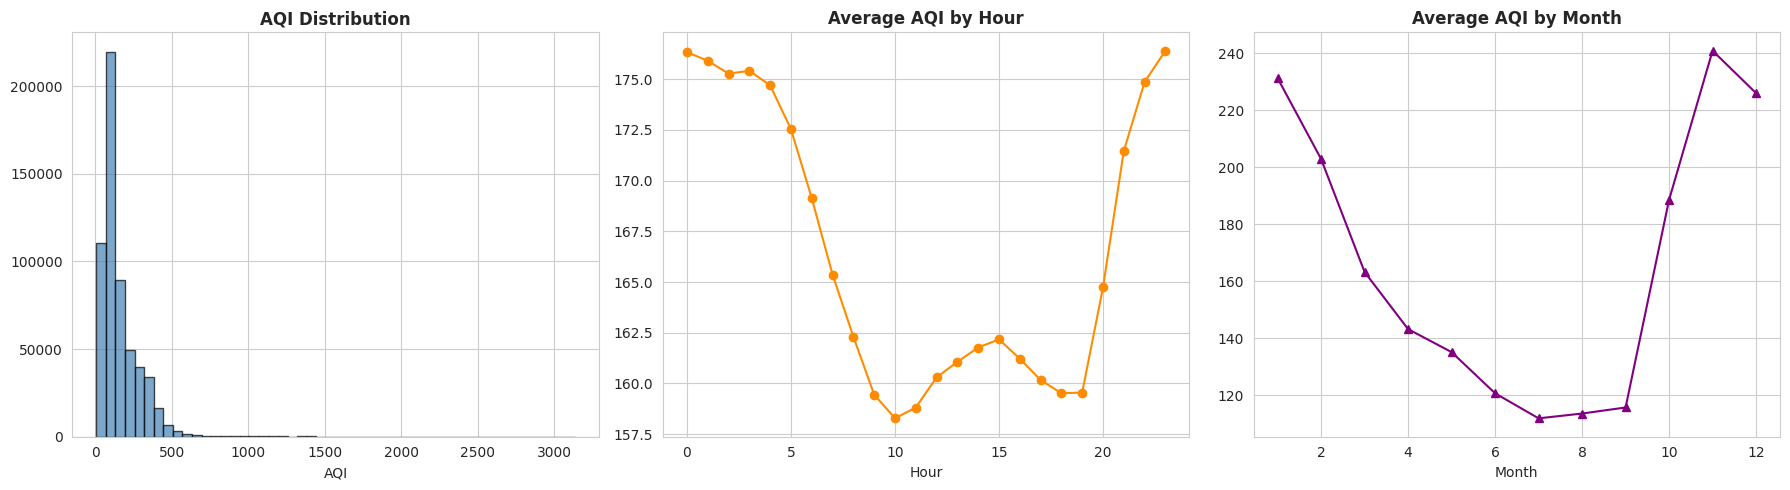


MODEL TRAINING - PER-CITY
Top cities: ['Delhi', 'Bengaluru', 'Lucknow', 'Chennai', 'Hyderabad']

CITY: Delhi (samples: 47646)
  1h | Linear Regression  | MAE:   2.896 | RMSE:   4.011 | R²: 0.9989
  1h | Random Forest      | MAE:   4.275 | RMSE:   5.969 | R²: 0.9977
  1h | XGBoost            | MAE:   3.391 | RMSE:   5.596 | R²: 0.9979
  6h | Linear Regression  | MAE:  11.631 | RMSE:  15.099 | R²: 0.9850
  6h | Random Forest      | MAE:  13.135 | RMSE:  17.858 | R²: 0.9790
  6h | XGBoost            | MAE:  11.375 | RMSE:  15.667 | R²: 0.9838
  12h | Linear Regression  | MAE:  20.992 | RMSE:  27.884 | R²: 0.9487
  12h | Random Forest      | MAE:  21.532 | RMSE:  28.953 | R²: 0.9447
  12h | XGBoost            | MAE:  20.370 | RMSE:  27.515 | R²: 0.9501
  24h | Linear Regression  | MAE:  37.450 | RMSE:  50.230 | R²: 0.8335
  24h | Random Forest      | MAE:  39.858 | RMSE:  52.441 | R²: 0.8186
  24h | XGBoost            | MAE:  40.231 | RMSE:  52.866 | R²: 0.8156

CITY: Bengaluru (samples: 

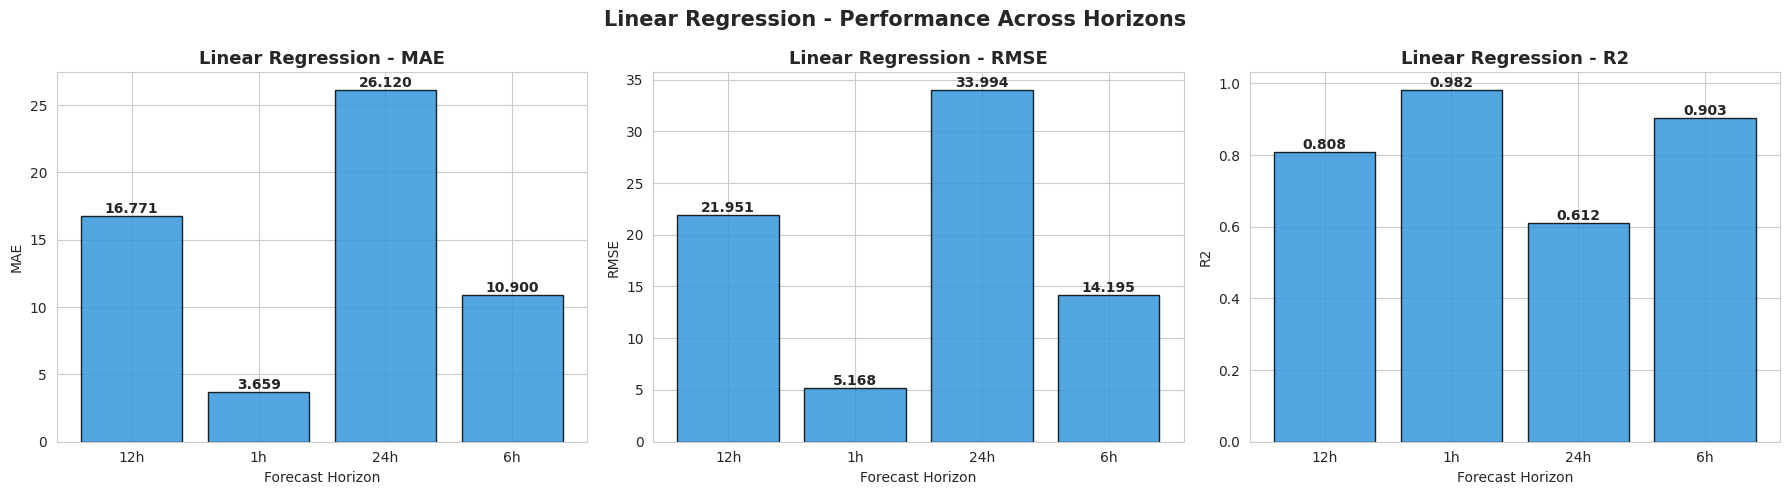

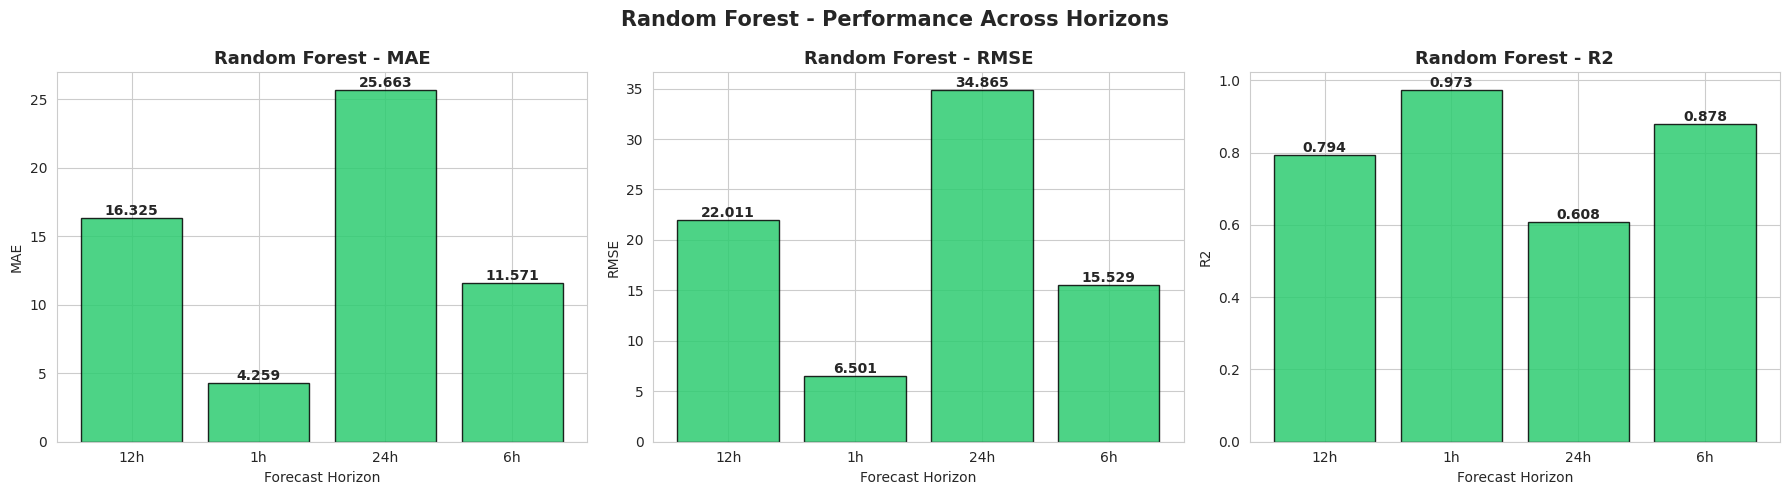

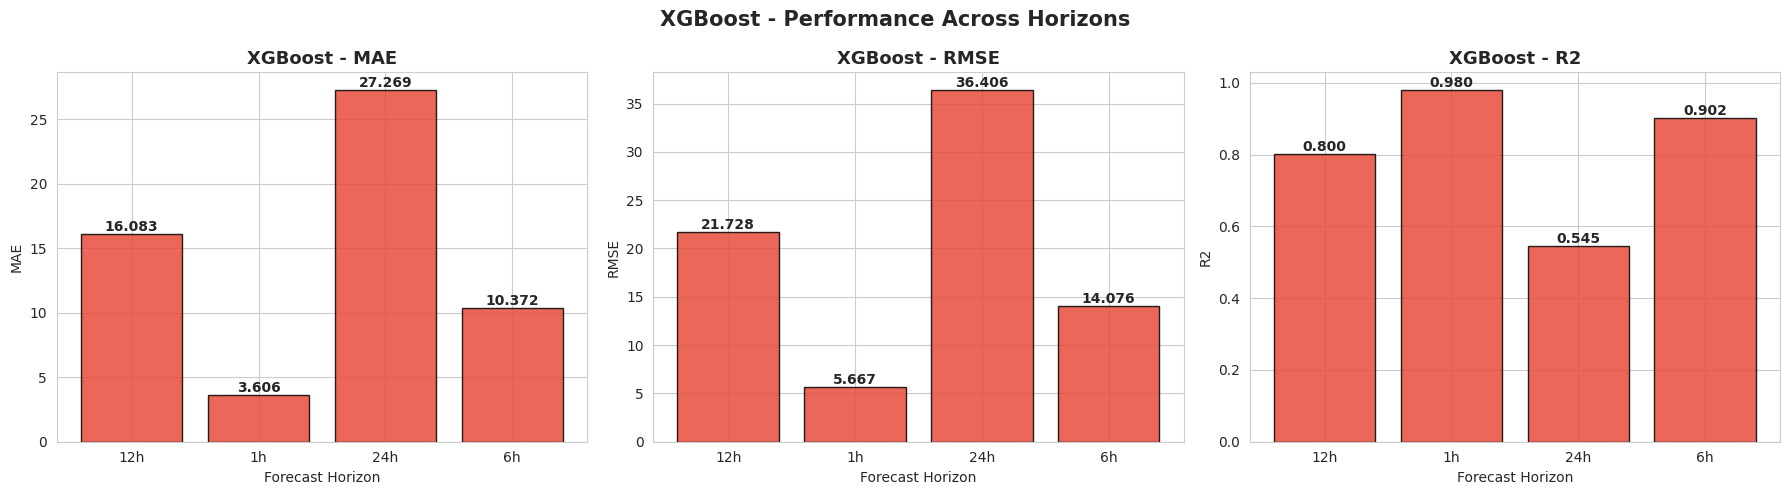

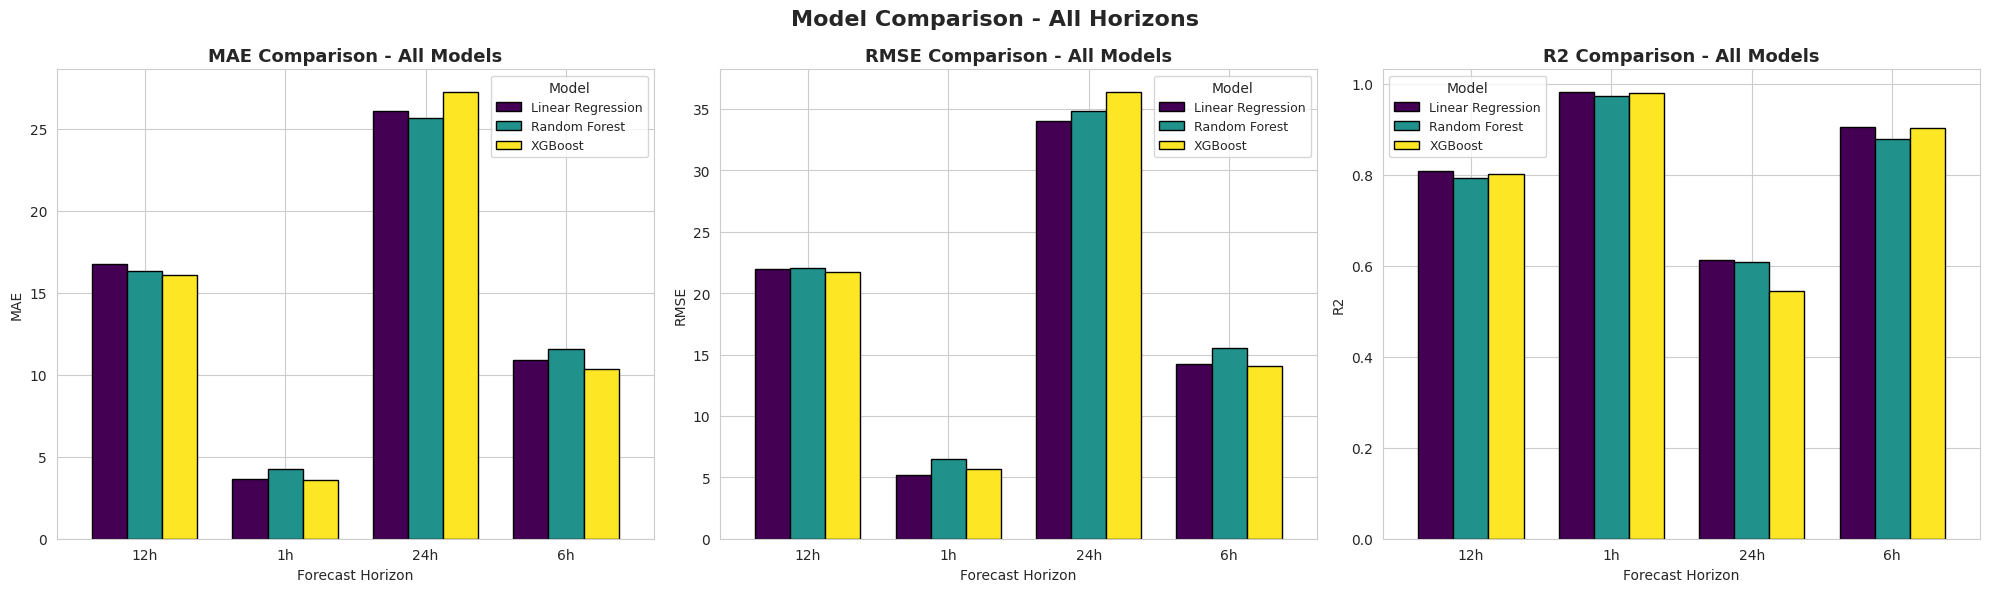

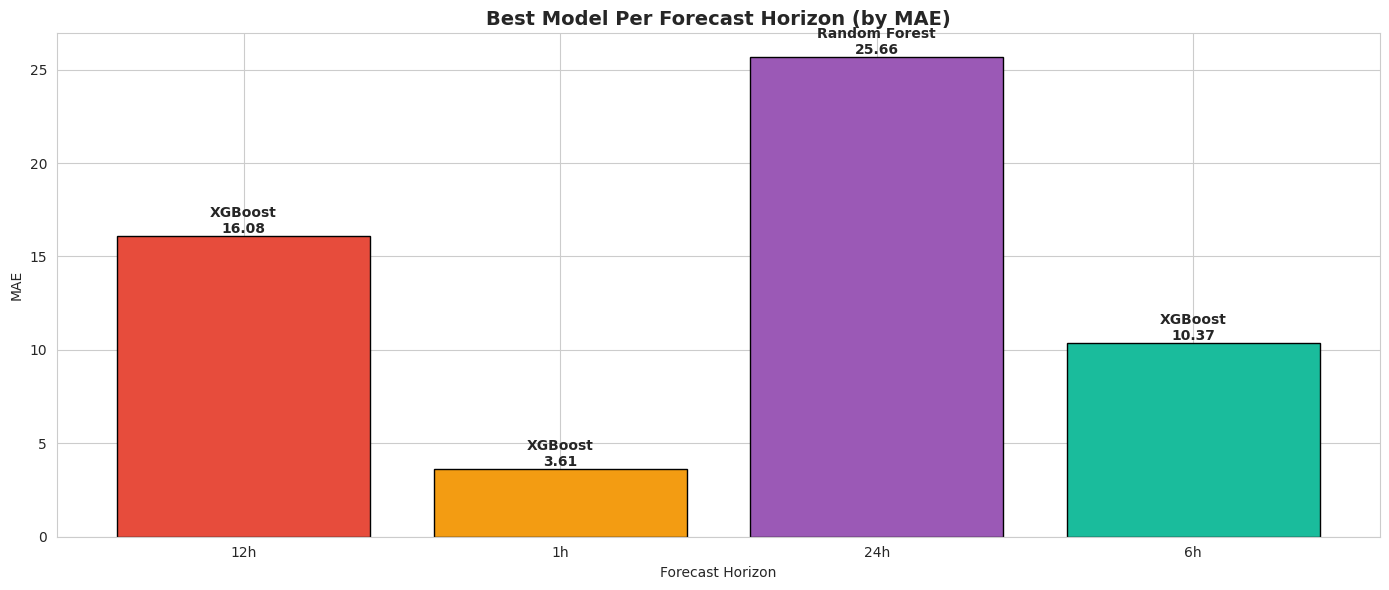

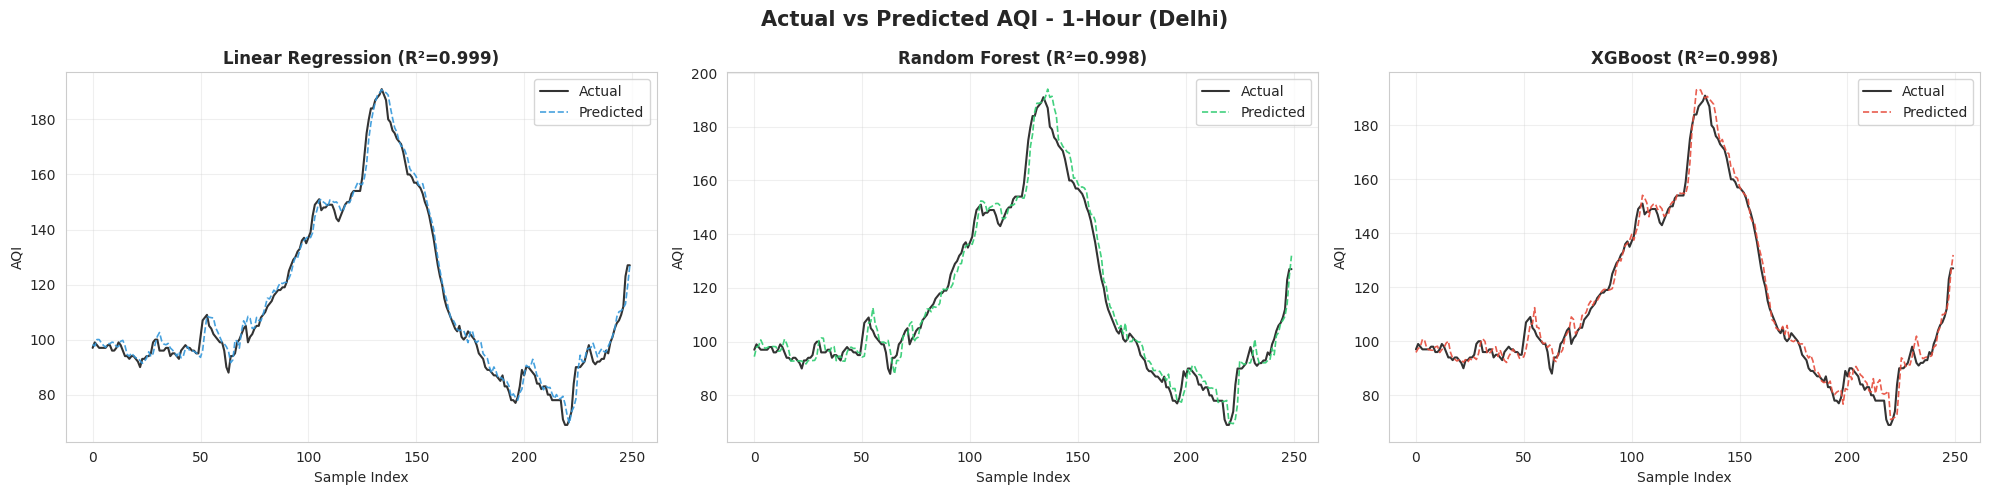

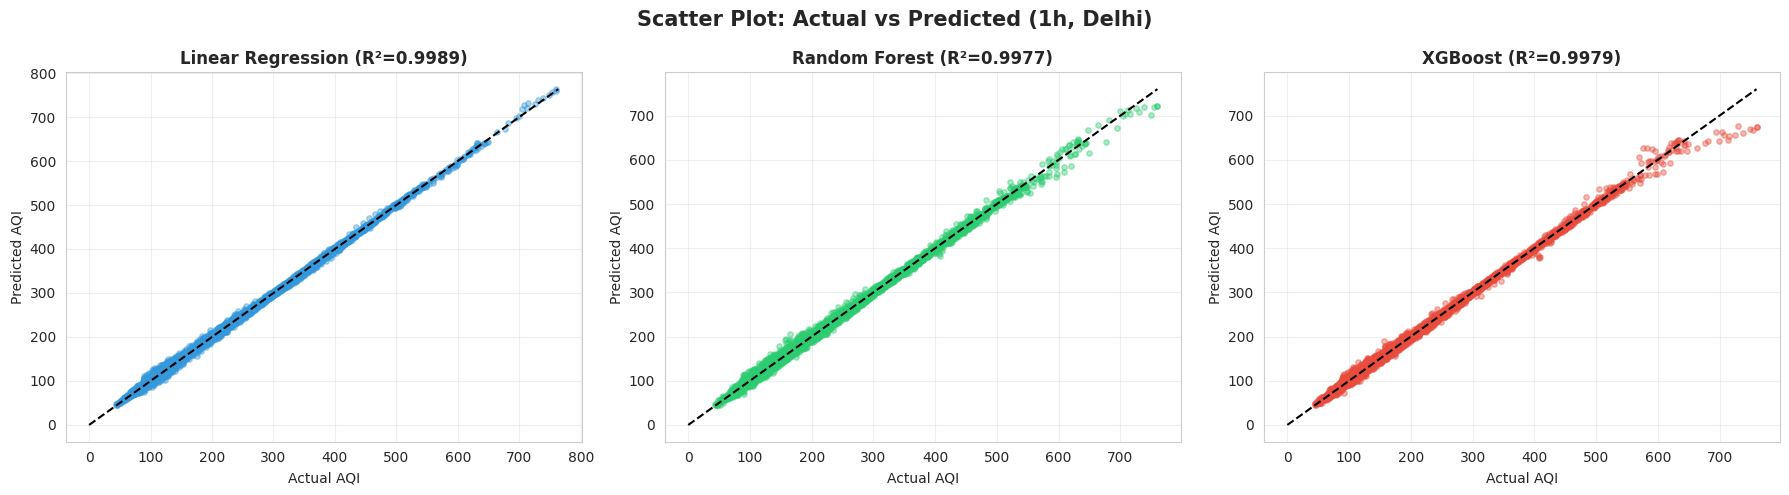

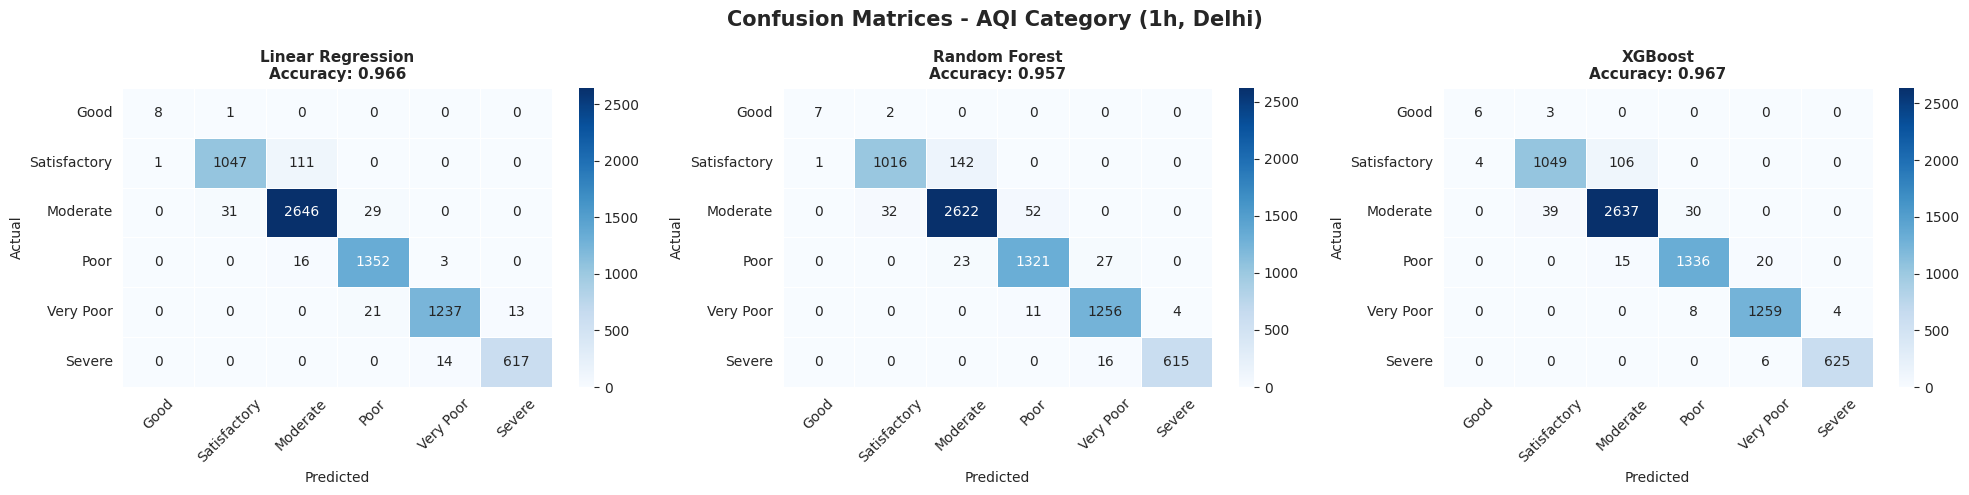


CLASSIFICATION METRICS:
            Model  Accuracy  Precision   Recall  F1-Score
Linear Regression  0.966419   0.966636 0.966419  0.966248
    Random Forest  0.956625   0.956986 0.956625  0.956327
          XGBoost  0.967119   0.967177 0.967119  0.966969


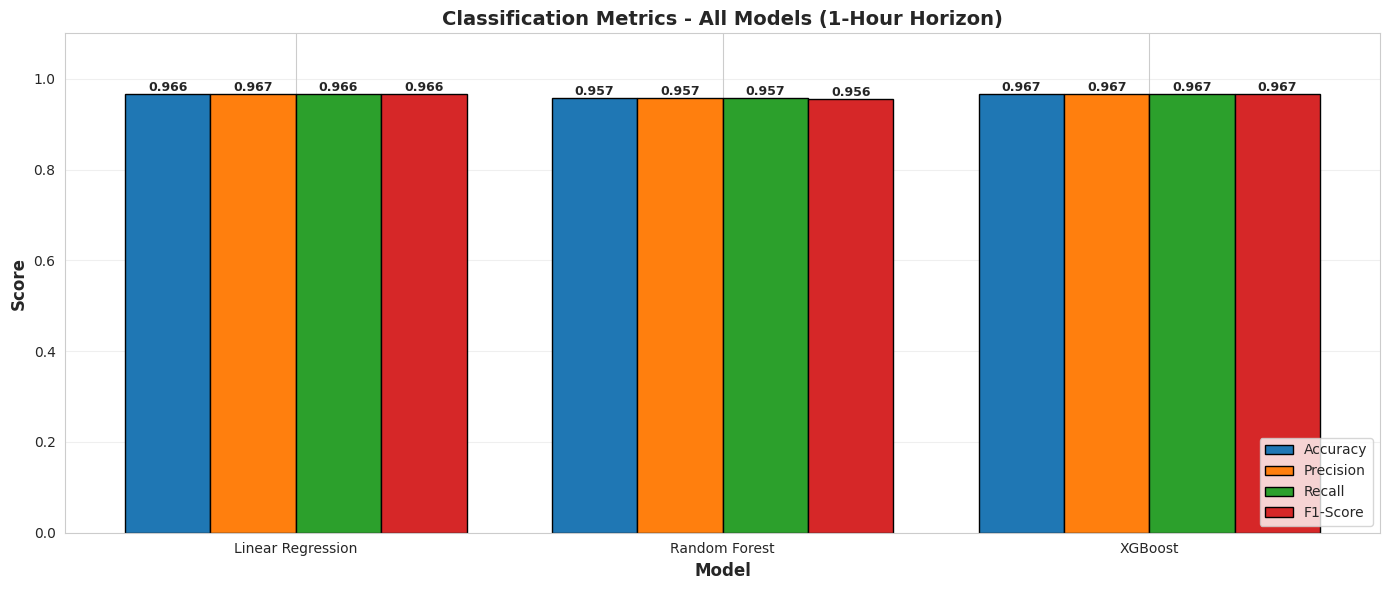

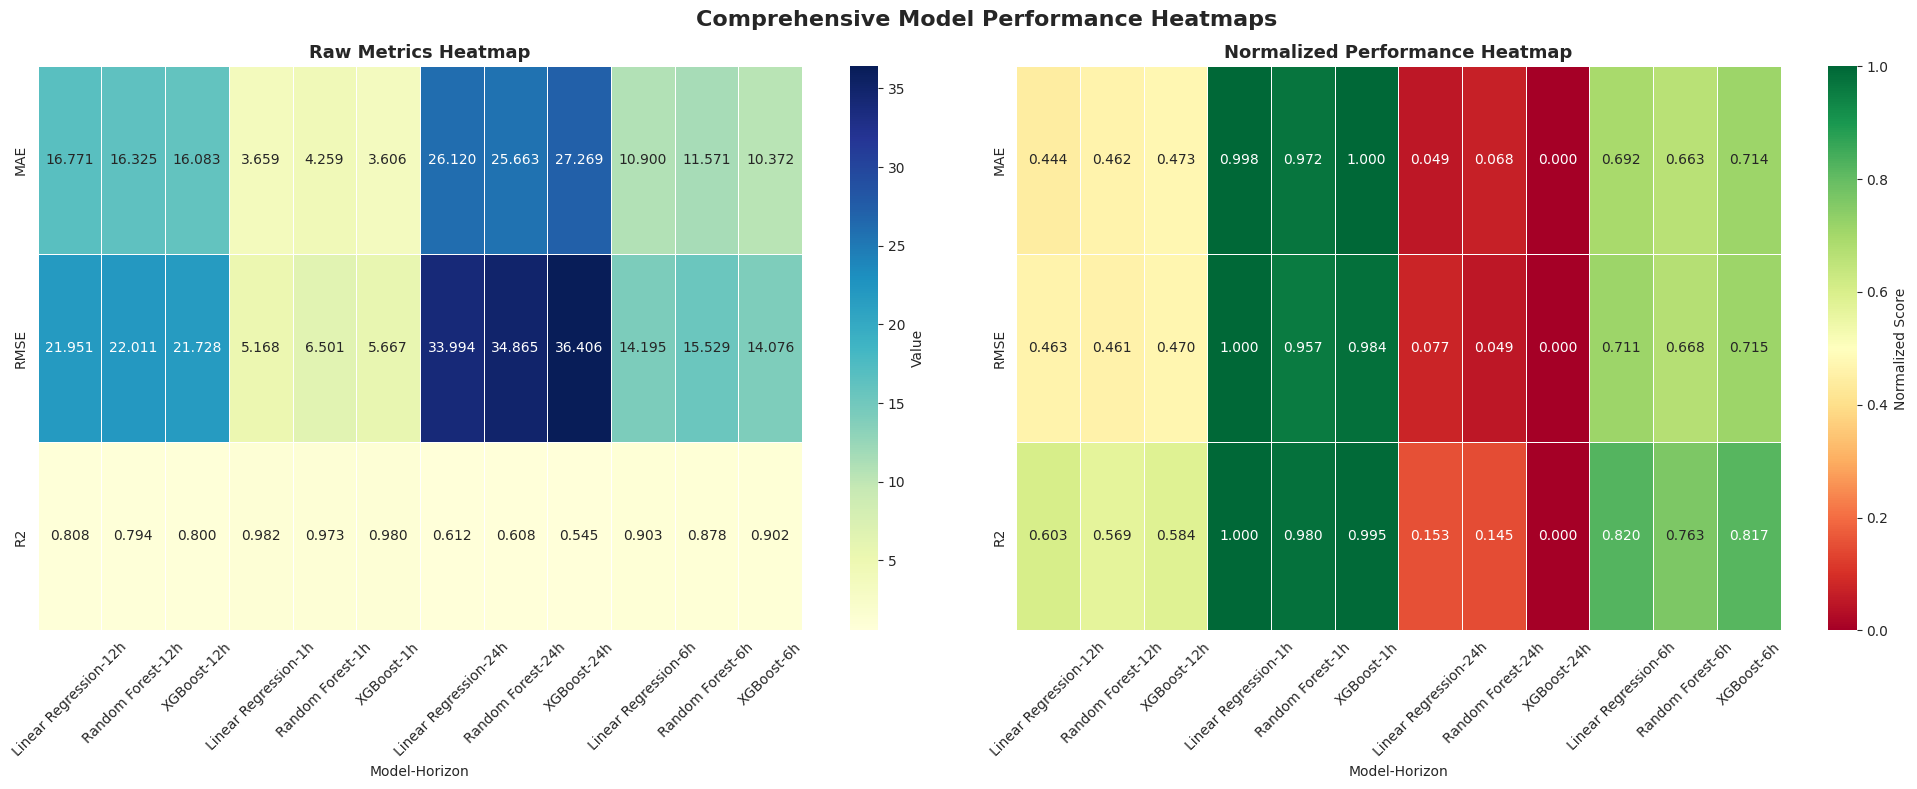

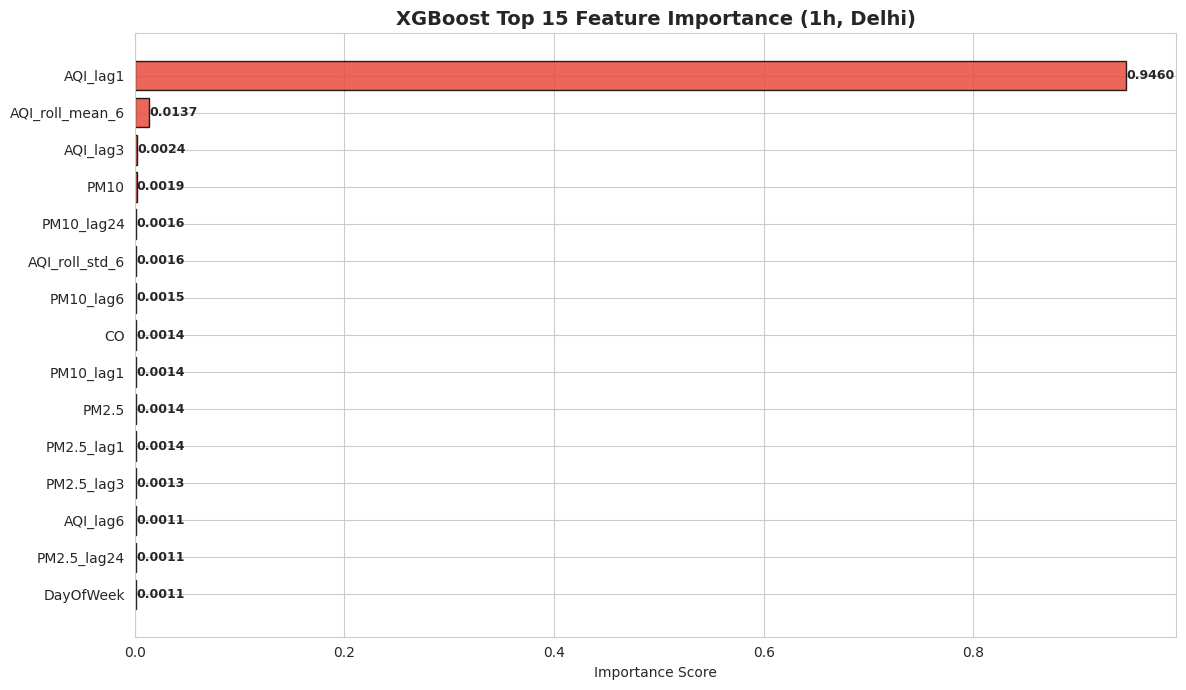


Generating uncertainty analysis...


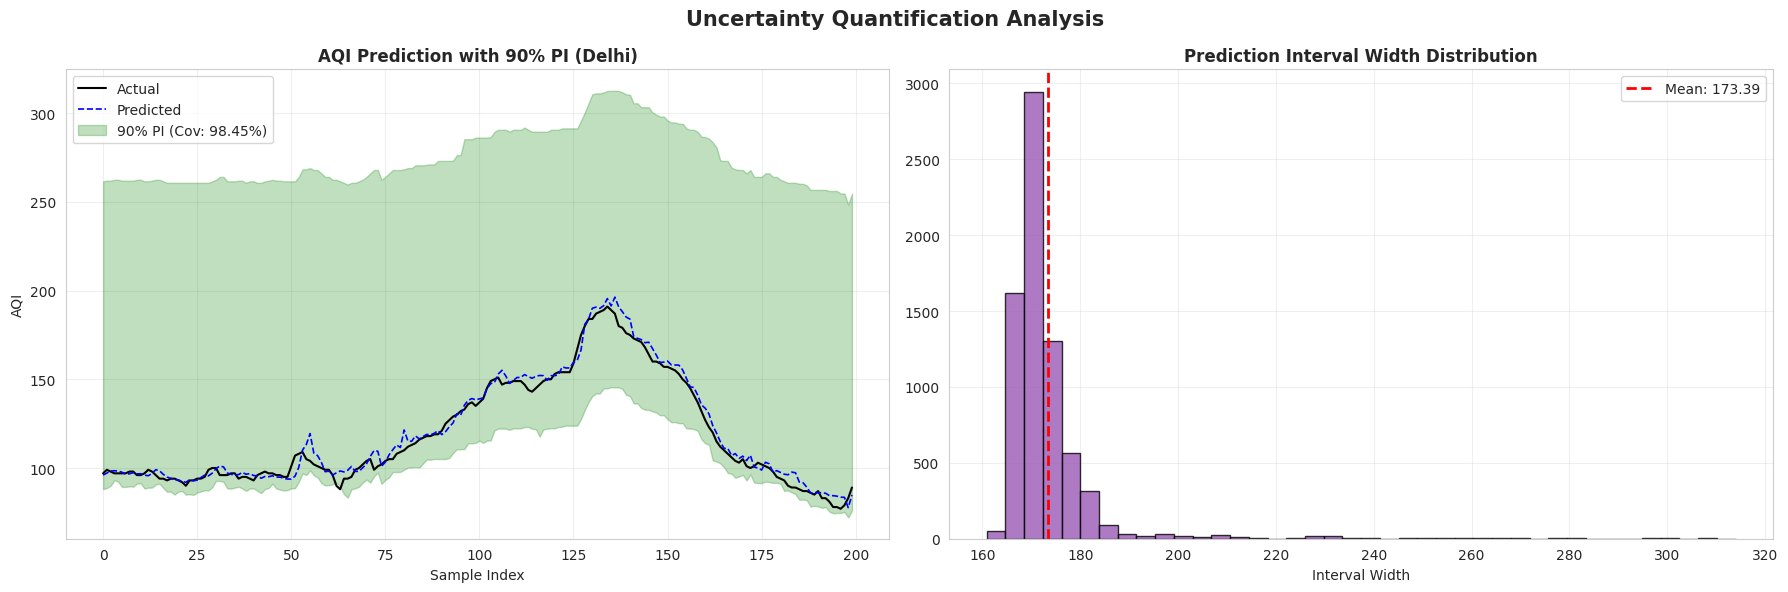

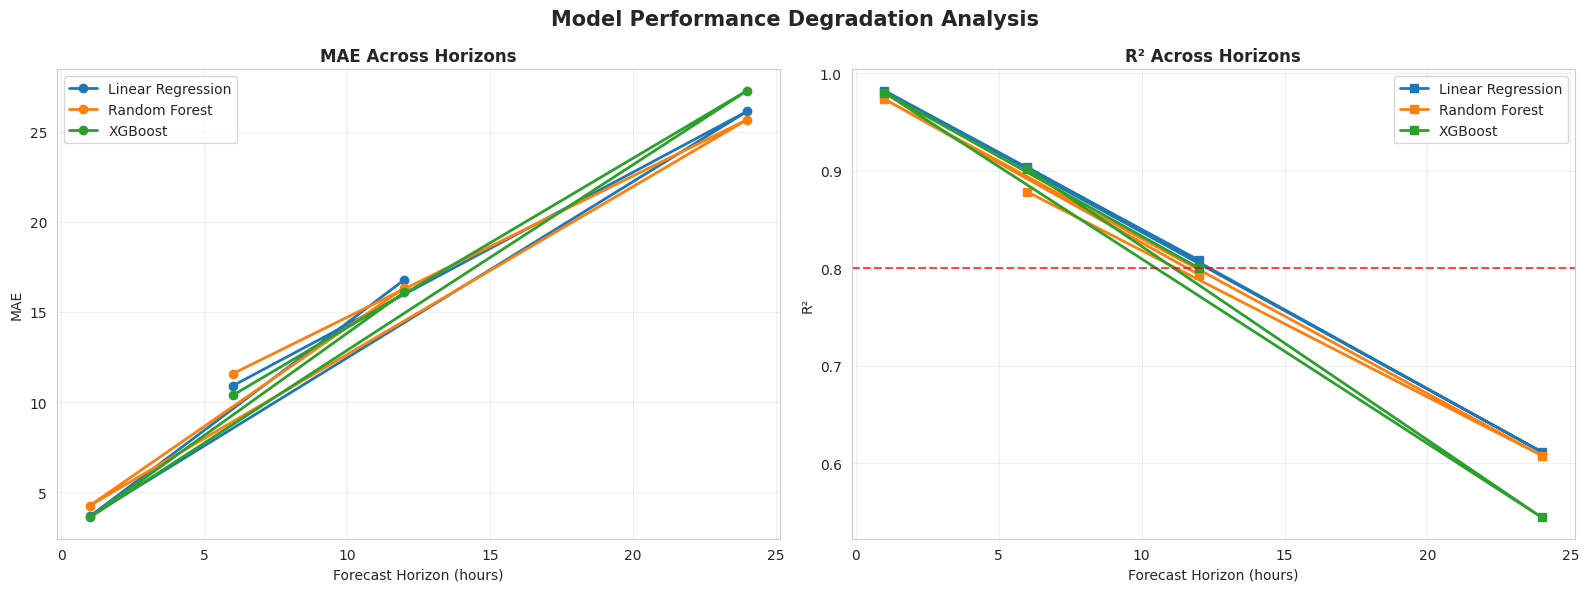


FINAL SUMMARY

>>> AVERAGE REGRESSION METRICS:
Horizon             Model       MAE      RMSE       R2
    12h Linear Regression 16.770718 21.950654 0.808279
    12h     Random Forest 16.325097 22.011392 0.793505
    12h           XGBoost 16.082552 21.728174 0.800241
     1h Linear Regression  3.659156  5.167959 0.982057
     1h     Random Forest  4.258733  6.501428 0.973381
     1h           XGBoost  3.606266  5.666869 0.979990
    24h Linear Regression 26.120119 33.994088 0.611598
    24h     Random Forest 25.662574 34.864964 0.607930
    24h           XGBoost 27.268605 36.405857 0.544507
     6h Linear Regression 10.899528 14.194590 0.903483
     6h     Random Forest 11.571205 15.529218 0.878261
     6h           XGBoost 10.372498 14.075873 0.901915

>>> CLASSIFICATION METRICS (1-Hour):
            Model  Accuracy  Precision   Recall  F1-Score
Linear Regression  0.966419   0.966636 0.966419  0.966248
    Random Forest  0.956625   0.956986 0.956625  0.956327
          XGBoost  0.9671

In [4]:
# =============================================================================
# EXPLAINABLE AND UNCERTAINTY-AWARE ML FOR SHORT-TERM AQI PREDICTION
# Fixed & Optimized - Fast Execution with Complete Results
# =============================================================================

import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import glob
import time

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer  # ← FIXED: Added missing import
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)
import xgboost as xgb

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("=" * 80)
print("EXPLAINABLE AND UNCERTAINTY-AWARE ML FOR AQI PREDICTION")
print("=" * 80)

START_TIME = time.time()

# =============================================================================
# 1. DATASET LOADING (FAST)
# =============================================================================

DATASET_ZIP_PATH = "/content/Air Quality Data in India (2015 - 2020).zip"
EXTRACT_PATH = "/content/air_quality_data"

if not os.path.exists(EXTRACT_PATH):
    with zipfile.ZipFile(DATASET_ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

all_files = glob.glob(os.path.join(EXTRACT_PATH, "**", "*.csv"), recursive=True)
hourly_files = [f for f in all_files if 'hour' in f.lower() and 'city' in f.lower()]
if not hourly_files:
    hourly_files = [f for f in all_files if 'hour' in f.lower()]
DATA_PATH = hourly_files[0] if hourly_files else all_files[0]

df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {df.shape}")

# Identify columns
datetime_col = [c for c in df.columns if 'date' in c.lower() or 'time' in c.lower()][0]
aqi_col = [c for c in df.columns if c.lower() == 'aqi'][0]

# Fast cleaning
df[datetime_col] = pd.to_datetime(df[datetime_col], errors='coerce')
df = df.dropna(subset=[datetime_col, aqi_col])
df = df.sort_values(['City', datetime_col]).reset_index(drop=True)

pollutant_cols = [c for c in df.columns if any(p in c.lower() for p in
    ['pm2.5','pm10','no','no2','nox','nh3','co','so2','o3','benzene','toluene','xylene'])
    and c != aqi_col and 'bucket' not in c.lower()]

# FAST missing value handling: global median (much faster than per-city loop)
df[pollutant_cols] = df[pollutant_cols].fillna(df[pollutant_cols].median())

print(f"Pollutants: {len(pollutant_cols)} | Rows: {len(df)}")

# =============================================================================
# 2. FAST FEATURE ENGINEERING (Optimized)
# =============================================================================

# Temporal features
df['Hour'] = df[datetime_col].dt.hour
df['DayOfWeek'] = df[datetime_col].dt.dayofweek
df['Month'] = df[datetime_col].dt.month
df['Hour_sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
df['Hour_cos'] = np.cos(2 * np.pi * df['Hour'] / 24)
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

# Lag features (grouped by city - CRITICAL)
for lag in [1, 3, 6, 12, 24]:
    df[f'{aqi_col}_lag{lag}'] = df.groupby('City')[aqi_col].shift(lag)
    for p in pollutant_cols[:3]:  # Reduced to 3 for speed
        df[f'{p}_lag{lag}'] = df.groupby('City')[p].shift(lag)

# Rolling features (reduced windows for speed)
for w in [6, 12, 24]:
    df[f'{aqi_col}_roll_mean_{w}'] = df.groupby('City')[aqi_col].transform(lambda x: x.rolling(w).mean())
    df[f'{aqi_col}_roll_std_{w}'] = df.groupby('City')[aqi_col].transform(lambda x: x.rolling(w).std())

# Multi-horizon targets
HORIZONS = [1, 6, 12, 24]
for h in HORIZONS:
    df[f'AQI_target_{h}h'] = df.groupby('City')[aqi_col].shift(-h)

df = df.dropna().reset_index(drop=True)
print(f"After feature engineering: {df.shape}")

# Feature columns
exclude = [datetime_col, aqi_col, 'City'] + [f'AQI_target_{h}h' for h in HORIZONS]
feature_cols = [c for c in df.columns if c not in exclude and df[c].dtype in ['int64','float64','int32','float32']]
print(f"Total features: {len(feature_cols)}")

# =============================================================================
# 3. FAST EDA (Quick Visualizations)
# =============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(df[aqi_col], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('AQI Distribution', fontweight='bold')
axes[0].set_xlabel('AQI')

df.groupby('Hour')[aqi_col].mean().plot(ax=axes[1], color='darkorange', marker='o')
axes[1].set_title('Average AQI by Hour', fontweight='bold')

df.groupby('Month')[aqi_col].mean().plot(ax=axes[2], color='purple', marker='^')
axes[2].set_title('Average AQI by Month', fontweight='bold')
plt.tight_layout()
plt.savefig('eda_overview.png', dpi=120, bbox_inches='tight')
plt.show()

# =============================================================================
# 4. PER-CITY MODEL TRAINING (FAST - Top 5 Cities Only)
# =============================================================================

print("\n" + "=" * 80)
print("MODEL TRAINING - PER-CITY")
print("=" * 80)

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1),
    'XGBoost': xgb.XGBRegressor(n_estimators=80, max_depth=7, learning_rate=0.1, random_state=42, n_jobs=-1)
}

# Use top 5 cities only for speed
city_counts = df['City'].value_counts()
TOP_CITIES = city_counts[city_counts > 3000].index.tolist()[:5]
print(f"Top cities: {TOP_CITIES}")

all_results = []
all_predictions = {}
all_actuals = {}

for city in TOP_CITIES:
    city_df = df[df['City'] == city].sort_values(datetime_col).reset_index(drop=True)
    print(f"\n{'='*60}")
    print(f"CITY: {city} (samples: {len(city_df)})")
    print(f"{'='*60}")

    for horizon in HORIZONS:
        y = city_df[f'AQI_target_{horizon}h'].values
        X = city_df[feature_cols].values

        n = len(X)
        train_end = int(0.70 * n)
        val_end = int(0.85 * n)

        X_train, y_train = X[:train_end], y[:train_end]
        X_test, y_test = X[val_end:], y[val_end:]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        for name, model in models.items():
            model.fit(X_train_scaled, y_train)
            y_pred = model.predict(X_test_scaled)

            mae = mean_absolute_error(y_test, y_pred)
            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            r2 = r2_score(y_test, y_pred)

            all_results.append({
                'City': city, 'Horizon': f'{horizon}h', 'Model': name,
                'MAE': mae, 'RMSE': rmse, 'R2': r2
            })

            key = f"{city}_{horizon}h_{name}"
            all_predictions[key] = y_pred
            all_actuals[key] = y_test

            print(f"  {horizon}h | {name:18s} | MAE: {mae:7.3f} | RMSE: {rmse:7.3f} | R²: {r2:.4f}")

results_df = pd.DataFrame(all_results)
print(f"\nTotal training time: {time.time() - START_TIME:.2f}s")

# =============================================================================
# 5. AVERAGE RESULTS ACROSS CITIES
# =============================================================================

avg_results = results_df.groupby(['Horizon', 'Model']).agg({
    'MAE': 'mean', 'RMSE': 'mean', 'R2': 'mean'
}).reset_index()

print("\n" + "=" * 80)
print("AVERAGE RESULTS ACROSS ALL CITIES")
print("=" * 80)
print(avg_results.to_string(index=False))

# =============================================================================
# 6. INDIVIDUAL MODEL GRAPHS (MAE, RMSE, R²)
# =============================================================================

print("\nGenerating individual model graphs...")

model_names = ['Linear Regression', 'Random Forest', 'XGBoost']
colors = ['#3498db', '#2ecc71', '#e74c3c']

for model_name in model_names:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    model_data = avg_results[avg_results['Model'] == model_name]

    for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
        bars = ax.bar(model_data['Horizon'], model_data[metric],
                      color=colors[model_names.index(model_name)], edgecolor='black', alpha=0.85)
        ax.set_title(f'{model_name} - {metric}', fontsize=13, fontweight='bold')
        ax.set_xlabel('Forecast Horizon')
        ax.set_ylabel(metric)
        for bar, v in zip(bars, model_data[metric]):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                    f'{v:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

    plt.suptitle(f'{model_name} - Performance Across Horizons', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f'{model_name.replace(" ","_")}_results.png', dpi=120, bbox_inches='tight')
    plt.show()

# =============================================================================
# 7. MODEL COMPARISON GRAPH
# =============================================================================

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
    pivot = avg_results.pivot(index='Horizon', columns='Model', values=metric)
    pivot = pivot[model_names]
    pivot.plot(kind='bar', ax=ax, edgecolor='black', colormap='viridis', width=0.75)
    ax.set_title(f'{metric} Comparison - All Models', fontsize=13, fontweight='bold')
    ax.set_xlabel('Forecast Horizon')
    ax.set_ylabel(metric)
    ax.legend(title='Model', fontsize=9)
    ax.tick_params(axis='x', rotation=0)

plt.suptitle('Model Comparison - All Horizons', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

# =============================================================================
# 8. BEST MODEL PER HORIZON
# =============================================================================

fig, ax = plt.subplots(figsize=(14, 6))
best_per_horizon = avg_results.loc[avg_results.groupby('Horizon')['MAE'].idxmin()]
bars = ax.bar(best_per_horizon['Horizon'], best_per_horizon['MAE'],
              color=['#e74c3c', '#f39c12', '#9b59b6', '#1abc9c'], edgecolor='black')
for bar, model, val in zip(bars, best_per_horizon['Model'], best_per_horizon['MAE']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f'{model}\n{val:.2f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title('Best Model Per Forecast Horizon (by MAE)', fontsize=14, fontweight='bold')
ax.set_xlabel('Forecast Horizon')
ax.set_ylabel('MAE')
plt.tight_layout()
plt.savefig('best_model_per_horizon.png', dpi=120, bbox_inches='tight')
plt.show()

# =============================================================================
# 9. ACTUAL VS PREDICTED (Top City, 1h Horizon)
# =============================================================================

viz_city = TOP_CITIES[0]
y_test_1h = all_actuals[f"{viz_city}_1h_XGBoost"]
preds_1h = {name: all_predictions[f"{viz_city}_1h_{name}"] for name in model_names}

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for i, name in enumerate(model_names):
    sample_n = min(250, len(y_test_1h))
    axes[i].plot(y_test_1h[:sample_n], label='Actual', color='black', linewidth=1.5, alpha=0.8)
    axes[i].plot(preds_1h[name][:sample_n], label='Predicted', color=colors[i],
                 linewidth=1.2, linestyle='--', alpha=0.9)
    r2 = r2_score(y_test_1h, preds_1h[name])
    axes[i].set_title(f'{name} (R²={r2:.3f})', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Sample Index')
    axes[i].set_ylabel('AQI')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.suptitle(f'Actual vs Predicted AQI - 1-Hour ({viz_city})', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=120, bbox_inches='tight')
plt.show()

# =============================================================================
# 10. SCATTER PLOTS (Actual vs Predicted)
# =============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, name in enumerate(model_names):
    axes[i].scatter(y_test_1h, preds_1h[name], alpha=0.4, s=15, color=colors[i])
    max_val = max(y_test_1h.max(), preds_1h[name].max())
    axes[i].plot([0, max_val], [0, max_val], 'k--', linewidth=1.5)
    r2 = r2_score(y_test_1h, preds_1h[name])
    axes[i].set_title(f'{name} (R²={r2:.4f})', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Actual AQI')
    axes[i].set_ylabel('Predicted AQI')
    axes[i].grid(True, alpha=0.3)

plt.suptitle(f'Scatter Plot: Actual vs Predicted (1h, {viz_city})', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('scatter_plot.png', dpi=120, bbox_inches='tight')
plt.show()

# =============================================================================
# 11. CLASSIFICATION METRICS (Accuracy, Precision, Recall, F1)
# =============================================================================

def categorize_aqi(aqi):
    if aqi <= 50: return 0
    elif aqi <= 100: return 1
    elif aqi <= 200: return 2
    elif aqi <= 300: return 3
    elif aqi <= 400: return 4
    else: return 5

category_labels = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
y_actual_cat = np.array([categorize_aqi(v) for v in y_test_1h])

category_metrics = []
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for i, name in enumerate(model_names):
    y_pred_cat = np.array([categorize_aqi(v) for v in preds_1h[name]])

    acc = accuracy_score(y_actual_cat, y_pred_cat)
    prec = precision_score(y_actual_cat, y_pred_cat, average='weighted', zero_division=0)
    rec = recall_score(y_actual_cat, y_pred_cat, average='weighted', zero_division=0)
    f1 = f1_score(y_actual_cat, y_pred_cat, average='weighted', zero_division=0)

    category_metrics.append({'Model': name, 'Accuracy': acc, 'Precision': prec,
                             'Recall': rec, 'F1-Score': f1})

    cm = confusion_matrix(y_actual_cat, y_pred_cat, labels=[0,1,2,3,4,5])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=category_labels, yticklabels=category_labels,
                cbar=True, linewidths=0.5)
    axes[i].set_title(f'{name}\nAccuracy: {acc:.3f}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].tick_params(axis='y', rotation=0)

plt.suptitle(f'Confusion Matrices - AQI Category (1h, {viz_city})', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

cat_metrics_df = pd.DataFrame(category_metrics)
print("\nCLASSIFICATION METRICS:")
print(cat_metrics_df.to_string(index=False))

# =============================================================================
# 12. CLASSIFICATION METRICS BAR CHART
# =============================================================================

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(cat_metrics_df))
width = 0.2

for i, metric in enumerate(['Accuracy', 'Precision', 'Recall', 'F1-Score']):
    bars = ax.bar(x + i*width, cat_metrics_df[metric], width, label=metric, edgecolor='black')
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xlabel('Model', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Classification Metrics - All Models (1-Hour Horizon)', fontsize=14, fontweight='bold')
ax.set_xticks(x + 1.5*width)
ax.set_xticklabels(cat_metrics_df['Model'])
ax.legend(loc='lower right')
ax.set_ylim(0, 1.1)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('classification_metrics.png', dpi=120, bbox_inches='tight')
plt.show()

# =============================================================================
# 13. COMPREHENSIVE METRICS HEATMAP
# =============================================================================

heatmap_data = []
for _, row in avg_results.iterrows():
    heatmap_data.append({
        'Model-Horizon': f"{row['Model']}-{row['Horizon']}",
        'MAE': row['MAE'], 'RMSE': row['RMSE'], 'R2': row['R2']
    })

heatmap_df = pd.DataFrame(heatmap_data).set_index('Model-Horizon')

norm_df = heatmap_df.copy()
norm_df['MAE'] = 1 - (norm_df['MAE'] - norm_df['MAE'].min()) / (norm_df['MAE'].max() - norm_df['MAE'].min() + 1e-8)
norm_df['RMSE'] = 1 - (norm_df['RMSE'] - norm_df['RMSE'].min()) / (norm_df['RMSE'].max() - norm_df['RMSE'].min() + 1e-8)
norm_df['R2'] = (norm_df['R2'] - norm_df['R2'].min()) / (norm_df['R2'].max() - norm_df['R2'].min() + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(heatmap_df.T, annot=True, fmt='.3f', cmap='YlGnBu', ax=axes[0],
            linewidths=0.5, cbar_kws={'label': 'Value'})
axes[0].set_title('Raw Metrics Heatmap', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(norm_df.T, annot=True, fmt='.3f', cmap='RdYlGn', ax=axes[1],
            linewidths=0.5, cbar_kws={'label': 'Normalized Score'}, vmin=0, vmax=1)
axes[1].set_title('Normalized Performance Heatmap', fontsize=13, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Comprehensive Model Performance Heatmaps', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('metrics_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

# =============================================================================
# 14. FEATURE IMPORTANCE (XGBoost)
# =============================================================================

city_df_viz = df[df['City'] == viz_city].sort_values(datetime_col).reset_index(drop=True)
X_viz = city_df_viz[feature_cols].values
y_viz = city_df_viz['AQI_target_1h'].values

n = len(X_viz)
train_end = int(0.70 * n)
scaler_viz = StandardScaler()
X_train_viz = scaler_viz.fit_transform(X_viz[:train_end])

xgb_model = xgb.XGBRegressor(n_estimators=80, max_depth=7, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train_viz, y_viz[:train_end])

importance = xgb_model.feature_importances_
top_idx = np.argsort(importance)[-15:]

fig, ax = plt.subplots(figsize=(12, 7))
ax.barh([feature_cols[i] for i in top_idx], importance[top_idx],
        color='#e74c3c', edgecolor='black', alpha=0.85)
ax.set_title(f'XGBoost Top 15 Feature Importance (1h, {viz_city})', fontsize=14, fontweight='bold')
ax.set_xlabel('Importance Score')
for i, v in enumerate(importance[top_idx]):
    ax.text(v, i, f'{v:.4f}', va='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

# =============================================================================
# 15. UNCERTAINTY QUANTIFICATION (Prediction Intervals)
# =============================================================================

print("\nGenerating uncertainty analysis...")

val_end = int(0.85 * n)
X_test_viz = scaler_viz.transform(X_viz[val_end:])
y_test_viz = y_viz[val_end:]

quantile_preds = {}
for q in [0.05, 0.50, 0.95]:
    q_model = xgb.XGBRegressor(n_estimators=80, max_depth=7, learning_rate=0.1,
                                objective='reg:quantileerror', quantile_alpha=q,
                                random_state=42, n_jobs=-1)
    q_model.fit(X_train_viz, y_viz[:train_end])
    quantile_preds[q] = q_model.predict(X_test_viz)

lower = quantile_preds[0.05]
upper = quantile_preds[0.95]
median = quantile_preds[0.50]

coverage = np.mean((y_test_viz >= lower) & (y_test_viz <= upper))
mpiw = np.mean(upper - lower)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sample_n = min(200, len(y_test_viz))

axes[0].plot(y_test_viz[:sample_n], label='Actual', color='black', linewidth=1.5)
axes[0].plot(median[:sample_n], label='Predicted', color='blue', linewidth=1.2, linestyle='--')
axes[0].fill_between(range(sample_n), lower[:sample_n], upper[:sample_n],
                      alpha=0.25, color='green', label=f'90% PI (Cov: {coverage:.2%})')
axes[0].set_title(f'AQI Prediction with 90% PI ({viz_city})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sample Index')
axes[0].set_ylabel('AQI')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(upper - lower, bins=40, color='#9b59b6', edgecolor='black', alpha=0.8)
axes[1].axvline(mpiw, color='red', linestyle='--', linewidth=2, label=f'Mean: {mpiw:.2f}')
axes[1].set_title('Prediction Interval Width Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Interval Width')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Uncertainty Quantification Analysis', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('uncertainty_analysis.png', dpi=120, bbox_inches='tight')
plt.show()

# =============================================================================
# 16. PERFORMANCE DEGRADATION GRAPH
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for name in model_names:
    model_data = avg_results[avg_results['Model'] == name]
    horizons = [int(h.replace('h','')) for h in model_data['Horizon']]
    axes[0].plot(horizons, model_data['MAE'], marker='o', linewidth=2, label=name)
    axes[1].plot(horizons, model_data['R2'], marker='s', linewidth=2, label=name)

axes[0].set_title('MAE Across Horizons', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Forecast Horizon (hours)')
axes[0].set_ylabel('MAE')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title('R² Across Horizons', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Forecast Horizon (hours)')
axes[1].set_ylabel('R²')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].axhline(y=0.80, color='red', linestyle='--', alpha=0.7, label='Target R²=0.80')

plt.suptitle('Model Performance Degradation Analysis', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('performance_degradation.png', dpi=120, bbox_inches='tight')
plt.show()

# =============================================================================
# 17. FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("FINAL SUMMARY")
print("=" * 80)

print("\n>>> AVERAGE REGRESSION METRICS:")
print(avg_results.to_string(index=False))

print("\n>>> CLASSIFICATION METRICS (1-Hour):")
print(cat_metrics_df.to_string(index=False))

print(f"\n>>> UNCERTAINTY:")
print(f"  90% PI Coverage: {coverage:.4f} ({coverage*100:.2f}%)")
print(f"  Mean PI Width: {mpiw:.4f}")

print("\n>>> BEST MODEL PER HORIZON:")
for h in HORIZONS:
    best = avg_results[avg_results['Horizon'] == f'{h}h'].nsmallest(1, 'MAE').iloc[0]
    print(f"  {h}h: {best['Model']} (MAE={best['MAE']:.3f}, R²={best['R2']:.4f})")

print("\n>>> OVERALL BEST MODEL:")
model_avg = avg_results.groupby('Model')['MAE'].mean().sort_values()
for model, mae in model_avg.items():
    print(f"  {model}: {mae:.3f}")

TOTAL_TIME = time.time() - START_TIME
print(f"\n{'='*80}")
print(f"TOTAL EXECUTION TIME: {TOTAL_TIME:.2f} seconds ({TOTAL_TIME/60:.2f} minutes)")
print(f"{'='*80}")